# Modelin Eğitim ve Doğrulama Süreçlerini Yönetme
Bu örnekte, bir modelin hem eğitim hem de doğrulama sürecini nasıl takip edebileceğimizi göreceğiz.
- Eğitim verisi ile öğrenme
- Doğrulama verisi ile genelleme testi
- Eğitim ve doğrulama performansını grafikle izleme

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import tensorflow as tf

print("TensorFlow sürümü:", tf.__version__)


TensorFlow sürümü: 2.18.0


## XOR Veri Seti

In [2]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]])

y = np.array([0, 1, 1, 0])


## Model Oluşturma

In [3]:
model = Sequential()
model.add(Dense(4, input_shape=(2,), activation='relu'))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17 (68.00 B)

 Trainable params: 17 (68.00 B)

 Non-trainable params: 0 (0.00 B)

## Modelin Eğitim ve Doğrulama Süreci
`validation_split=0.5` ile verinin yarısı doğrulama için ayrılır.

In [6]:
history = model.fit(X, y, epochs=100, validation_split=0.5, verbose=0)
print("Eğitim tamamlandı.")

Eğitim tamamlandı.


## Eğitim ve Doğrulama Performansı
Grafikler, modelin hem eğitim hem de doğrulama sürecindeki başarı ve kaybı gösterir.

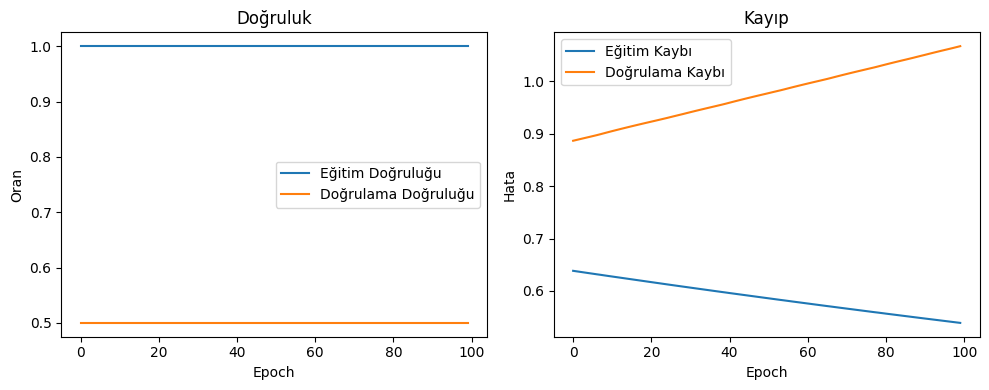

In [7]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim Doğruluğu')
plt.plot(history.history['val_accuracy'], label='Doğrulama Doğruluğu')
plt.title("Doğruluk")
plt.xlabel("Epoch")
plt.ylabel("Oran")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim Kaybı')
plt.plot(history.history['val_loss'], label='Doğrulama Kaybı')
plt.title("Kayıp")
plt.xlabel("Epoch")
plt.ylabel("Hata")
plt.legend()

plt.tight_layout()
plt.show()


## Tahmin Sonuçları

In [8]:
tahminler = model.predict(X)
print("Ham Tahminler:")
print(tahminler)
print("Yuvarlanmış Tahminler:")
print(np.round(tahminler))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
Ham Tahminler:
[[0.45977008]
 [0.6307622 ]
 [0.7268213 ]
 [0.83704126]]
Yuvarlanmış Tahminler:
[[0.]
 [1.]
 [1.]
 [1.]]
